# Explorar el modelo de mundo: `partial5x5_expert_local`

Este notebook sirve para ver **qué aprendió el modelo de mundo** del run `cookie_partial_hall5_view5_s0_expert_local` y qué le faltó. No entrena nada y funciona con CPU, aunque con GPU responde más rápido.

Este run es distinto a los de la semana 22:

- Vista parcial de **5×5** (`cookie_partial_hall5_view5`), pasillos de 5 celdas, 450.000 pasos, entrenado en local.
- Los datos los recogió **solo el experto** (`trainer.data_mix.expert=1`, `random_policy=False`), no la política random. El buffer era de 200.000 pasos.
- En Drive está solo lo necesario para el explorador y TensorBoard (`latest.pt`, `.hydra/`, `metrics.jsonl`, `events.out.tfevents...`). **No se subió `replay/`**, así que el diagnóstico usa `metrics.jsonl` en vez del buffer.

1. **Diagnóstico desde las métricas**: galletas del experto que llenó el replay frente a las del actor en evaluación, y las curvas de entrenamiento.
2. **Explorador interactivo**: mueves al agente con las flechas y ves, lado a lado, la vista real, lo que el modelo *entiende* cuando ve la imagen (posterior), lo que *predice sin ver* (sueño o prior), el error entre ambos, y la recompensa, el `continue`, el valor y la política que asigna a cada estado.
3. **TensorBoard**: curvas y videos `open_loop` guardados durante el entrenamiento.

Antes de empezar: la carpeta es de otra cuenta, así que necesita un acceso directo en *Mi unidad* (clic derecho → *Organizar → Agregar acceso directo*). Si no, no aparece al montar Drive.

## 1. Montar Drive y encontrar el run

In [1]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

# Nombre de la carpeta del run (el acceso directo en Mi unidad tiene este nombre).
NOMBRE_RUN = "cookie_partial_hall5_view5_s0_expert_local"

# La busca hasta dos niveles dentro de Mi unidad (acceso directo incluido).
# Si el nombre no calza exacto, prueba con cualquier carpeta que termine en "expert_local".
raiz = Path("/content/drive/MyDrive")
patrones = [NOMBRE_RUN, f"*/{NOMBRE_RUN}", f"*/*/{NOMBRE_RUN}",
            "*expert_local", "*/*expert_local", "*/*/*expert_local"]
CARPETA = next((p for patron in patrones for p in sorted(raiz.glob(patron)) if p.is_dir()), None)
# Si no la encuentra, escribe la ruta a mano:
# CARPETA = Path("/content/drive/MyDrive/cookie_partial_hall5_view5_s0_expert_local")
assert CARPETA is not None, f"No encontré {NOMBRE_RUN}: agrega el acceso directo en Mi unidad o escribe la ruta en CARPETA."

# La carpeta puede ser un run (tiene latest.pt) o contener varios runs.
if (CARPETA / "latest.pt").exists():
    RUNS = {CARPETA.name: CARPETA}
else:
    RUNS = {p.name: p for p in sorted(CARPETA.iterdir()) if (p / "latest.pt").exists()}
assert RUNS, f"No hay ningún latest.pt en {CARPETA}"

print("Carpeta:", CARPETA)
for nombre, run in RUNS.items():
    archivos = sorted(x.name for x in run.iterdir())
    print(" -", nombre, "→", ", ".join(archivos))

Mounted at /content/drive
Carpeta: /content/drive/MyDrive/cookie_partial_hall5_view5_s0_expert_local
 - cookie_partial_hall5_view5_s0_expert_local → .hydra, console.log, events.out.tfevents.1794456413.Joaco.48087.0, latest.pt, metrics.jsonl, status.json


## 2. Diagnóstico del run

Si la carpeta trae `replay/`, se leen `reward` e `is_first` del buffer (sin cargar las imágenes). Si no (como en este run), se usa `metrics.jsonl`: ahí queda cada episodio de entrenamiento con sus galletas (`episode/score`) y quién lo jugó (`data/episodes_expert`, `_actor`, `_random`).

Lo que no esté en esos datos, el modelo de mundo no lo pudo aprender. Se compara con `episode/eval_score`, las galletas que consigue el **actor aprendido** en evaluación.

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd


def metricas(run):
    """metrics.jsonl como DataFrame (una fila por línea; cada línea trae solo algunas métricas)."""
    filas = []
    for linea in (Path(run) / "metrics.jsonl").read_text().splitlines():
        try:
            filas.append(json.loads(linea))
        except json.JSONDecodeError:
            continue
    return pd.DataFrame(filas)


def serie(df, nombre):
    """Una métrica contra el paso, sin las filas donde no aparece."""
    return df[["step", nombre]].dropna().set_index("step")[nombre] if nombre in df else pd.Series(dtype=float)


def campo(run, nombre):
    """Un campo del replay como memmap (no se carga a RAM)."""
    s = Path(run) / "replay" / "storage"
    m = json.loads((s / "meta.json").read_text())[nombre]
    return np.memmap(s / f"{nombre}.memmap", dtype=np.dtype(m["dtype"].split(".")[-1]), mode="r", shape=tuple(m["shape"]))


def orden_replay(run):
    """Índices del buffer ordenados del paso más antiguo al más nuevo (es circular)."""
    r = Path(run) / "replay"
    n = json.loads((r / "storage" / "storage_metadata.json").read_text())["len"]
    cursor = json.loads((r / "writer" / "metadata.json").read_text())["cursor"]
    return (np.arange(n) + cursor) % n


def episodios(run):
    """Galletas por episodio de los datos de entrenamiento.
    Con replay/: episodios completos del buffer (cortados con is_first).
    Sin replay/: episodios de metrics.jsonl que caben en el tamaño del buffer."""
    if (Path(run) / "replay" / "storage").exists():
        orden = orden_replay(run)
        reward = np.asarray(campo(run, "reward"))[:, 0, 0][orden]
        first = np.asarray(campo(run, "is_first"))[:, 0, 0][orden]
        inicios = np.flatnonzero(first)
        # Lo anterior al primer is_first está cortado por el buffer circular y el último
        # puede estar a medias: se descartan los dos.
        galletas = np.add.reduceat((reward > 0).astype(np.int64), inicios)[:-1]
        return pd.DataFrame({"largo": np.diff(inicios), "galletas": galletas, "fuente": "replay"})
    df = metricas(run)
    eps = df.dropna(subset=["episode/score"]).copy()
    # Solo los episodios que todavía estarían en el buffer al final.
    from omegaconf import OmegaConf
    tam = float(OmegaConf.load(Path(run) / ".hydra" / "config.yaml").buffer.max_size)
    eps = eps[eps["step"] > eps["step"].max() - tam]
    quien = eps[[c for c in eps if c.startswith("data/episodes_")]].idxmax(axis=1).str.replace("data/episodes_", "")
    return pd.DataFrame({"largo": eps["episode/length"].values, "galletas": eps["episode/score"].values,
                         "fuente": quien.values})


def resumen_run(run):
    eps = episodios(run)
    df = metricas(run)
    fila = {
        "run": Path(run).name,
        "datos de": ", ".join(sorted(eps["fuente"].unique())),
        "episodios en replay": len(eps),
        "% episodios con ≥1 galleta": 100 * (eps["galletas"] > 0).mean(),
        "galletas/episodio (datos)": eps["galletas"].mean(),
    }
    evals = serie(df, "episode/eval_score")
    if len(evals):
        fila["eval actor (último)"] = evals.iloc[-1]
        fila["eval actor (máx)"] = evals.max()
    return fila


tabla = pd.DataFrame([resumen_run(run) for run in RUNS.values()]).set_index("run")
tabla.round(3)

,datos de,episodios en replay,% episodios con ≥1 galleta,galletas/episodio (datos),eval actor (último),eval actor (máx)
run,,,,,,
cookie_partial_hall5_view5_s0_expert_local,expert,246,100.0,20.736,0.0,0.0


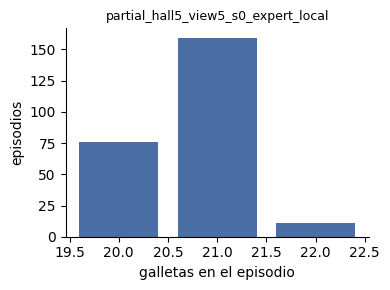

In [3]:
# Cómo se reparten las galletas por episodio en los datos de entrenamiento de cada run.
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, len(RUNS), figsize=(4 * len(RUNS), 3), sharey=True, squeeze=False)
for eje, (nombre, run) in zip(ejes[0], RUNS.items()):
    eps = episodios(run)
    conteo = eps["galletas"].value_counts().sort_index()
    eje.bar(conteo.index, conteo.values, color="#4a6fa5")
    eje.set_title(nombre.replace("cookie_", ""), fontsize=9)
    eje.set_xlabel("galletas en el episodio")
    eje.spines[["top", "right"]].set_visible(False)
ejes[0, 0].set_ylabel("episodios")
plt.tight_layout()

**Cómo leerlo.** Con datos random, el problema típico es que casi ningún episodio tiene galletas y la cabeza de recompensa predice ~0 en todas partes. Con datos del **experto** pasa lo contrario: casi todos los episodios tienen ~20 galletas, pero el modelo solo vio **las trayectorias del experto**. Si el actor se desvía (gira donde el experto avanzaba, se queda quieto, entra a otra pieza), el modelo nunca vio esas situaciones y puede soñar cualquier cosa. Eso se revisa en el explorador.

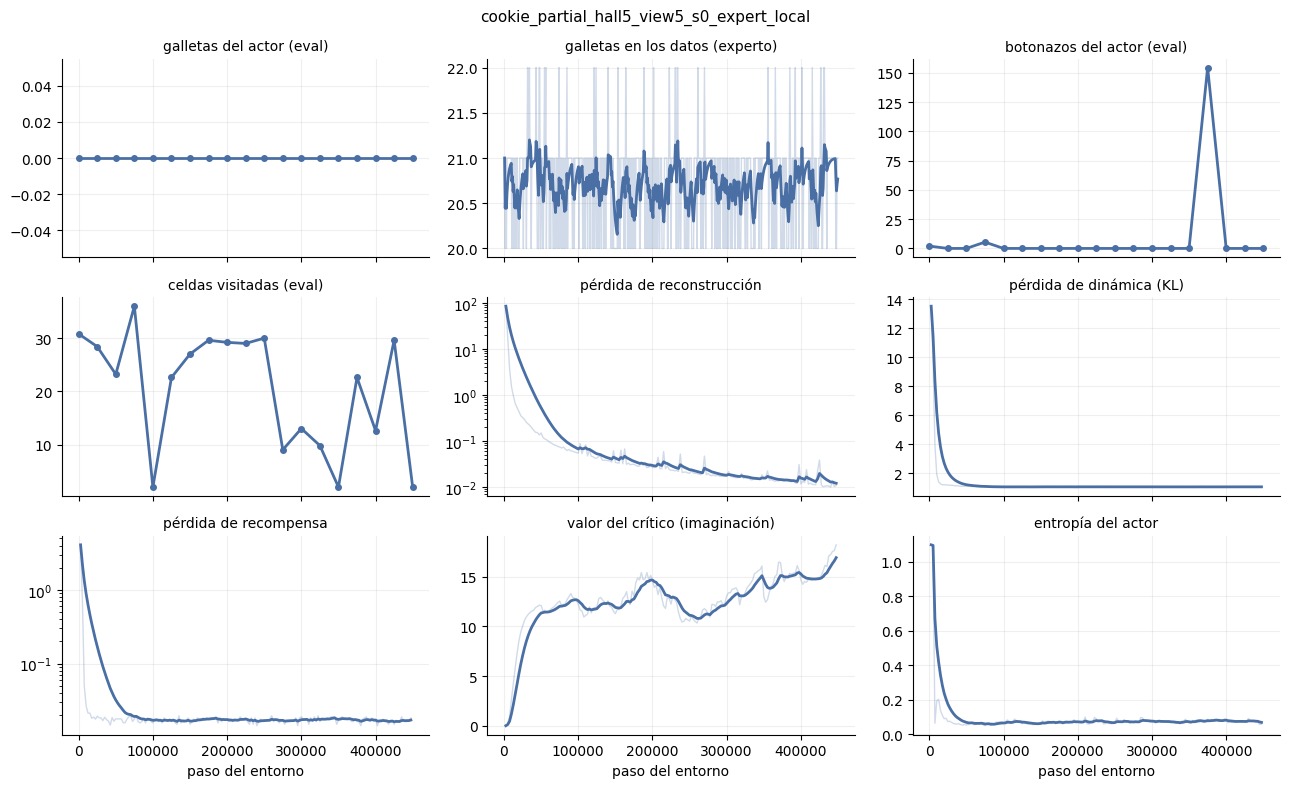

In [4]:
# Curvas de entrenamiento desde metrics.jsonl (lo mismo que muestra TensorBoard en Scalars, sin cargar el archivo de 700 MB).
GRAFICOS = [
    ("episode/eval_score", "galletas del actor (eval)"),
    ("episode/score", "galletas en los datos (experto)"),
    ("episode/eval_presses", "botonazos del actor (eval)"),
    ("episode/eval_cells", "celdas visitadas (eval)"),
    ("train/loss/image", "pérdida de reconstrucción"),
    ("train/loss/dyn", "pérdida de dinámica (KL)"),
    ("train/loss/rew", "pérdida de recompensa"),
    ("train/val", "valor del crítico (imaginación)"),
    ("train/action_entropy", "entropía del actor"),
]

for nombre, run in RUNS.items():
    df = metricas(run)
    fig, ejes = plt.subplots(3, 3, figsize=(13, 8), sharex=True)
    for eje, (clave, titulo) in zip(ejes.flat, GRAFICOS):
        s = serie(df, clave)
        if len(s) > 60:  # suaviza las métricas densas, como el slider de TensorBoard
            eje.plot(s.index, s.values, color="#4a6fa5", alpha=0.25, linewidth=1)
            s = s.ewm(alpha=0.2).mean()
        eje.plot(s.index, s.values, color="#4a6fa5", linewidth=2, marker="o" if len(s) < 40 else None, markersize=4)
        if clave.startswith("train/loss/image") or clave == "train/loss/rew":
            eje.set_yscale("log")
        eje.set_title(titulo, fontsize=10)
        eje.grid(alpha=0.2)
        eje.spines[["top", "right"]].set_visible(False)
    for eje in ejes[-1]:
        eje.set_xlabel("paso del entorno")
    fig.suptitle(nombre, fontsize=11)
    plt.tight_layout()
    plt.show()

**Qué dicen las métricas de este run** (`cookie_partial_hall5_view5_s0_expert_local`):

- El experto que llenó el replay consigue **~21 galletas por episodio** (816 pasos). El actor aprendido saca **0 en las 19 evaluaciones**, de 0 a 450k pasos.
- El modelo de mundo aprende bien *sobre los datos del experto*: la reconstrucción baja de 84 a ~0,01 y la pérdida de recompensa queda en ~0,02.
- El crítico cree que la cosa va bien: `train/val` sube de ~12 a ~18 y casi no varía entre estados (desviación ~0,3). Con 21 galletas cada 816 pasos y horizonte 333, el retorno del experto sería ~8,6, así que el valor parece **sobreestimado** y **plano**, y le da al actor poca señal para distinguir buenas de malas acciones.
- La entropía del actor cae de 1,1 (uniforme entre 3 acciones) a ~0,06 antes de los 50k pasos y no vuelve a subir: la política se volvió casi determinista muy pronto.
- En evaluación el actor casi no se mueve hacia el final (`eval_cells` baja a 2 y `eval_presses` a 0): se queda girando o pegado.

Hipótesis para revisar en el explorador: el actor nunca se entrenó con datos propios (`data_mix.actor=0`), así que el modelo solo conoce lo que hace el experto. Cuando el actor se sale de esas trayectorias, el sueño deja de parecerse a la realidad, pero sigue prediciendo recompensa y valor altos.

## 3. Instalar el código (Python 3.11 aparte, como en los notebooks de entrenamiento)

Toma unos minutos y hay que repetirlo en cada sesión nueva. Además del repo instala `gradio`, para la página interactiva, y `matplotlib`.

In [5]:
%%bash
if [ -d /content/r2dreamer-cookie ]; then
  cd /content/r2dreamer-cookie && git pull --ff-only
else
  git clone https://github.com/FabriRandon/r2dreamer-cookie.git /content/r2dreamer-cookie
fi
pip install -q uv
cd /content/r2dreamer-cookie
[ -d .venv ] || uv venv --python 3.11 .venv
uv pip install --python .venv/bin/python -e ".[cookie]" gradio matplotlib 2>&1 | tail -2

 + werkzeug==3.1.9
 + zipp==4.1.2


Cloning into '/content/r2dreamer-cookie'...
Using CPython 3.11.18
Creating virtual environment at: .venv
Activate with: source .venv/bin/activate


## 4. El explorador

La celda siguiente escribe `explorar_modelo.py` dentro del repo. Carga el agente igual que `watch.py`: config de `.hydra/` y pesos de `latest.pt`.

In [6]:
%%writefile /content/r2dreamer-cookie/explorar_modelo.py
"""Recorrer el modelo de mundo de un run del dominio cookie.

Abre una página (Gradio) donde se mueve al agente con botones o con las
flechas del teclado. Cada acción avanza dos cosas a la vez:

- el entorno real, y la reconstrucción del modelo cuando SÍ ve la observación
  (posterior: muestra qué retiene la representación);
- un sueño que NO ve nada desde la última sincronización (prior: muestra qué
  predice la dinámica).

Al lado aparecen la recompensa, el "continuar", el valor y la política que el
modelo asigna a cada estado, y una tira con lo que imagina el actor.

    python3 explorar_modelo.py --logdir /ruta/al/run            # abre la página
    python3 explorar_modelo.py --logdir /ruta/al/run --prueba out.png  # sin interfaz
"""

import argparse
import base64
import inspect
import io
import os
import pathlib
import random
import sys
import warnings

# Colab deja MPLBACKEND apuntando al backend inline del notebook, que no existe
# en el .venv de este script; matplotlib falla al importarse si no se cambia antes.
os.environ["MPLBACKEND"] = "Agg"
import matplotlib  # noqa: E402

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import torch  # noqa: E402
import torch.nn.functional as F  # noqa: E402
from omegaconf import OmegaConf  # noqa: E402
from PIL import Image, ImageDraw, ImageFont  # noqa: E402

warnings.filterwarnings("ignore")
sys.path.append(str(pathlib.Path(__file__).parent))

from dreamer import Dreamer  # noqa: E402
from envs import make_env  # noqa: E402

ACCIONES = ["izquierda", "derecha", "avanzar"]
LADO = 256  # tamaño en pantalla de las imágenes de 64x64


def cargar(logdir, device):
    config = OmegaConf.load(logdir / ".hydra" / "config.yaml")
    config.device = device
    config.model.compile = False
    env = make_env(config.env, 0)
    agent = Dreamer(config.model, env.observation_space, env.action_space).to(device)
    checkpoint = torch.load(logdir / "latest.pt", map_location=device, weights_only=False)
    agent.load_state_dict(checkpoint["agent_state_dict"])
    agent.eval()
    return config, env, agent, int(checkpoint.get("step", 0))


def agrandar(img, lado=LADO):
    return np.asarray(Image.fromarray(img).resize((lado, lado), Image.NEAREST))


class Explorador:
    """Estado del recorrido: entorno real, posterior y sueño."""

    def __init__(self, logdir, device):
        self.device = torch.device(device)
        self.config, self.env, self.agent, self.pasos_entrenados = cargar(pathlib.Path(logdir), device)
        self.rssm = self.agent.rssm
        self.cookie = self.env.unwrapped
        self.cookie._env.unwrapped.tile_size = 24
        self.n_acciones = self.agent.act_dim
        self.nombres = ACCIONES if self.n_acciones == len(ACCIONES) else [str(i) for i in range(self.n_acciones)]
        self.muestrear = False
        self.reiniciar(0)

    # --- piezas del modelo -------------------------------------------------

    def _onehot(self, i):
        return F.one_hot(torch.tensor([int(i)], device=self.device), self.n_acciones).float()

    def _stoch(self, logit):
        dist = self.rssm.get_dist(logit)
        return dist.rsample() if self.muestrear else dist.mode

    def _embed(self, obs):
        data = {"image": torch.as_tensor(np.asarray(obs["image"]), device=self.device)[None]}
        return self.agent.encoder(self.agent.preprocess(data))

    def _posterior(self, estado, accion, obs):
        """Un paso viendo la observación (como rssm.obs_step)."""
        stoch, deter = estado
        deter = self.rssm._deter_net(stoch, deter, accion)
        logit = self.rssm._obs_net(torch.cat([deter, self._embed(obs)], -1))
        return self._stoch(logit), deter

    def _prior(self, estado, accion):
        """Un paso sin ver nada (como rssm.img_step)."""
        stoch, deter = estado
        deter = self.rssm._deter_net(stoch, deter, accion)
        return self._stoch(self.rssm._img_net(deter)), deter

    @torch.no_grad()
    def _decodificar(self, estado):
        stoch, deter = estado
        img = self.agent.decoder(stoch[:, None], deter[:, None])["image"].mode()
        return (img[0, 0].clamp(0, 1).float().cpu().numpy() * 255).astype(np.uint8)

    @torch.no_grad()
    def _cabezas(self, estado):
        feat = self.rssm.get_feat(*estado)
        return {
            "r": float(self.agent.reward(feat).mode().item()),
            "c": float(self.agent.cont(feat).mean.item()),
            "v": float(self.agent.value(feat).mode().item()),
            "pi": self.agent.actor(feat).probs[0].float().cpu().numpy(),
        }

    # --- acciones del usuario ----------------------------------------------

    @torch.no_grad()
    def reiniciar(self, semilla):
        semilla = int(semilla)
        # cookie-env elige la esquina de la galleta con el random global.
        self.cookie._seed, self.cookie._seeded = semilla, False
        random.seed(semilla)
        self.obs = self.env.reset()
        cero = torch.zeros(1, self.n_acciones, device=self.device)
        self.post = self._posterior(self.rssm.initial(1), cero, self.obs)
        self.sueno = self.post
        self.paso_real, self.desde_sync, self.galletas, self.terminado = 0, 0, 0, False
        self.historia = []
        self._registrar(None, 0.0)

    @torch.no_grad()
    def sincronizar(self):
        self.sueno = self.post
        self.desde_sync = 0
        self._registrar(None, float("nan"))

    @torch.no_grad()
    def paso(self, i, mover_real=True):
        accion = self._onehot(i)
        self.sueno = self._prior(self.sueno, accion)
        self.desde_sync += 1
        recompensa = float("nan")
        if mover_real and not self.terminado:
            self.obs, recompensa, hecho, _ = self.env.step(accion[0].cpu().numpy())
            recompensa = float(recompensa)
            self.post = self._posterior(self.post, accion, self.obs)
            self.paso_real += 1
            self.galletas += int(recompensa > 0)
            self.terminado = bool(hecho)
        self._registrar(i, recompensa)

    @torch.no_grad()
    def accion_actor(self, mover_real=True):
        """La acción más probable del actor, desde el estado que se está mirando."""
        estado = self.post if mover_real else self.sueno
        return int(self._cabezas(estado)["pi"].argmax())

    @torch.no_grad()
    def imaginar_actor(self, horizonte=15):
        """Lo que entrena al actor: desde el posterior actual, el actor juega dentro del sueño."""
        estado, cuadros = self.post, []
        for _ in range(int(horizonte)):
            h = self._cabezas(estado)
            i = int(h["pi"].argmax())
            cuadros.append((self._decodificar(estado), h, i))
            estado = self._prior(estado, self._onehot(i))
        return self._tira(cuadros)

    # --- registro y dibujo -------------------------------------------------

    @torch.no_grad()
    def _registrar(self, accion, recompensa_real):
        hp, hs = self._cabezas(self.post), self._cabezas(self.sueno)
        real = np.asarray(self.obs["image"], dtype=np.float32) / 255
        error = float(((self._decodificar(self.sueno) / 255 - real) ** 2).mean())
        self.historia.append({"accion": accion, "r_real": recompensa_real, "post": hp, "sueno": hs, "error": error})

    @torch.no_grad()
    def vistas(self):
        real = np.asarray(self.obs["image"])
        recon = self._decodificar(self.post)
        sueno = self._decodificar(self.sueno)
        error = np.abs(sueno.astype(np.int16) - real.astype(np.int16)).astype(np.uint8)
        return {
            "mapa": self.cookie.render(),
            "real": agrandar(real),
            "recon": agrandar(recon),
            "sueno": agrandar(sueno),
            "error": agrandar(error),
            "info": self.resumen(),
            "grafico": self.grafico(),
        }

    def resumen(self):
        h = self.historia[-1]
        fila = lambda nombre, x: (  # noqa: E731
            f"| {nombre} | {x['r']:+.3f} | {x['c']:.2f} | {x['v']:+.2f} | "
            + " / ".join(f"{p:.2f}" for p in x["pi"])
            + " |"
        )
        ultima = "—" if h["accion"] is None else self.nombres[h["accion"]]
        r_real = "—" if np.isnan(h["r_real"]) else f"{h['r_real']:+.2f}"
        estado = "**terminó el episodio** (reinicia)" if self.terminado else ""
        return "\n".join([
            f"**Paso real {self.paso_real}** · galletas {self.galletas} · última acción: {ultima} · "
            f"recompensa real: {r_real} · el sueño lleva **{self.desde_sync} pasos sin ver** · "
            f"modelo entrenado {self.pasos_entrenados:,} pasos {estado}",
            "",
            "| estado | recompensa pred. | continuar | valor | actor π (" + " / ".join(self.nombres) + ") |",
            "|---|---|---|---|---|",
            fila("viendo (posterior)", h["post"]),
            fila(f"soñando ({self.desde_sync} sin ver)", h["sueno"]),
            "",
            f"Error del sueño frente a la vista real (MSE): {h['error']:.4f}",
        ])

    def grafico(self):
        hist = self.historia
        x = np.arange(len(hist))
        fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 4.2), sharex=True)
        a1.plot(x, [h["post"]["r"] for h in hist], label="recompensa pred. (viendo)")
        a1.plot(x, [h["sueno"]["r"] for h in hist], label="recompensa pred. (soñando)", linestyle="--")
        reales = [h["r_real"] for h in hist]
        a1.scatter(x, reales, s=12, color="black", label="recompensa real", zorder=3)
        a1.legend(fontsize=7, loc="best")
        a1.set_ylabel("recompensa")
        a2.plot(x, [h["error"] for h in hist], color="tab:red", label="error del sueño (MSE)")
        a2.plot(x, [h["post"]["v"] for h in hist], color="tab:green", label="valor (viendo)")
        a2.legend(fontsize=7, loc="best")
        a2.set_xlabel("acción del recorrido")
        fig.tight_layout()
        fig.canvas.draw()
        img = np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()
        plt.close(fig)
        return img

    def _tira(self, cuadros):
        # Filas de 5 cuadros, para que el texto se lea al ajustar la imagen al ancho.
        lado, alto_txt, por_fila = 160, 60, 5
        columnas = min(por_fila, len(cuadros))
        filas = -(-len(cuadros) // por_fila)
        tira = Image.new("RGB", (lado * columnas, (lado + alto_txt) * filas), (20, 20, 20))
        dibujo = ImageDraw.Draw(tira)
        fuente = ImageFont.load_default(size=14)
        for k, (img, h, i) in enumerate(cuadros):
            x, y = (k % por_fila) * lado, (k // por_fila) * (lado + alto_txt)
            tira.paste(Image.fromarray(img).resize((lado - 4, lado - 4), Image.NEAREST), (x + 2, y + 2))
            texto = f"t+{k}: {self.nombres[i]}\nr {h['r']:+.2f}   c {h['c']:.2f}\nv {h['v']:+.2f}"
            dibujo.multiline_text((x + 4, y + lado + 2), texto, fill=(230, 230, 230), font=fuente, spacing=3)
        return np.asarray(tira)


def a_html(img, titulo, pixelado):
    buf = io.BytesIO()
    Image.fromarray(img).save(buf, format="PNG")
    src = "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()
    estilo = "width:100%;height:auto;border-radius:4px;" + ("image-rendering:pixelated;" if pixelado else "")
    return (
        f'<figure style="margin:0"><figcaption style="font-size:13px;margin-bottom:4px">{titulo}</figcaption>'
        f'<img src="{src}" style="{estilo}"></figure>'
    )


def grilla(imagenes, columnas):
    celdas = "".join(a_html(*x) for x in imagenes)
    return f'<div style="display:grid;grid-template-columns:{columnas};gap:12px;align-items:start">{celdas}</div>'


def interfaz(exp):
    import gradio as gr

    # Las imágenes van incrustadas como data URI dentro de HTML. gr.Image las sirve
    # por URL, y esas URL se rompen detrás del proxy de Colab (se ven vacías).
    def mostrar():
        v = exp.vistas()
        arriba = grilla([
            (v["mapa"], "Mapa real (lo iluminado es lo que ve el agente)", False),
            (v["grafico"], "Historia del recorrido", False),
        ], columnas="1fr 1fr")
        vistas = grilla([
            (v["real"], "Vista real", True),
            (v["recon"], "Viendo: lo que entiende (reconstrucción)", True),
            (v["sueno"], f"Soñando: lo que predice sin ver ({exp.desde_sync} pasos)", True),
            (v["error"], "|sueño − real|", True),
        ], columnas="repeat(4, 1fr)")
        return [arriba, vistas, v["info"]]

    def mover(i, mover_real, muestrear):
        exp.muestrear = bool(muestrear)
        exp.paso(i, mover_real)
        return mostrar()

    def actor(mover_real, muestrear):
        exp.muestrear = bool(muestrear)
        exp.paso(exp.accion_actor(mover_real), mover_real)
        return mostrar()

    def actor_n(n, mover_real, muestrear):
        exp.muestrear = bool(muestrear)
        for _ in range(int(n)):
            if mover_real and exp.terminado:
                break
            exp.paso(exp.accion_actor(mover_real), mover_real)
        return mostrar()

    def sincronizar():
        exp.sincronizar()
        return mostrar()

    def reiniciar(semilla, muestrear):
        exp.muestrear = bool(muestrear)
        exp.reiniciar(semilla)
        return mostrar()

    teclado = """
<script>
document.addEventListener('keydown', (e) => {
  const tag = (document.activeElement || {}).tagName;
  if (tag === 'INPUT' || tag === 'TEXTAREA') return;
  const ids = {ArrowLeft: 'btn-izq', ArrowRight: 'btn-der', ArrowUp: 'btn-avz', s: 'btn-sync', a: 'btn-actor'};
  const el = ids[e.key] && document.getElementById(ids[e.key]);
  if (el) { e.preventDefault(); el.click(); }
});
</script>
"""
    # Gradio 6 recibe head en launch(); las versiones anteriores, en Blocks().
    head_en_launch = "head" in inspect.signature(gr.Blocks.launch).parameters
    with gr.Blocks(title="Modelo de mundo", **({} if head_en_launch else {"head": teclado})) as demo:
        gr.Markdown(
            "### Recorrer el modelo de mundo (versión 3: imágenes incrustadas)\n"
            "Flechas ← → ↑ (o los botones) mueven al agente. **S** sincroniza el sueño con la realidad, "
            "**A** juega la acción del actor. *Viendo* = el modelo recibe la imagen real en cada paso; "
            "*soñando* = solo recibe las acciones desde la última sincronización."
        )
        panel_arriba = gr.HTML()
        panel_vistas = gr.HTML()
        with gr.Row():
            b_izq = gr.Button("⟲ izquierda", elem_id="btn-izq")
            b_avz = gr.Button("↑ avanzar", elem_id="btn-avz", variant="primary")
            b_der = gr.Button("⟳ derecha", elem_id="btn-der")
        with gr.Row():
            b_actor = gr.Button("Acción del actor (A)", elem_id="btn-actor")
            n_actor = gr.Number(value=20, precision=0, label="pasos", minimum=1, maximum=500)
            b_actor_n = gr.Button("El actor juega N pasos")
            b_sync = gr.Button("Sincronizar sueño con la realidad (S)", elem_id="btn-sync")
        with gr.Row():
            mover_real = gr.Checkbox(value=True, label="Mover también el entorno real (si no, solo se sueña)")
            muestrear = gr.Checkbox(value=False, label="Muestrear el estado estocástico (si no, el más probable)")
            semilla = gr.Number(value=0, precision=0, label="semilla del episodio")
            b_reset = gr.Button("Reiniciar episodio")
        info = gr.Markdown()
        with gr.Accordion("Imaginación del actor (lo que usa para aprender)", open=False):
            horizonte = gr.Slider(1, 40, value=15, step=1, label="horizonte")
            b_imag = gr.Button("Imaginar desde el estado actual")
            tira = gr.HTML()

        salidas = [panel_arriba, panel_vistas, info]
        opciones = [mover_real, muestrear]
        for boton, i in ((b_izq, 0), (b_der, 1), (b_avz, 2)):
            boton.click(lambda m, s, i=i: mover(i, m, s), opciones, salidas)
        b_actor.click(actor, opciones, salidas)
        b_actor_n.click(actor_n, [n_actor, *opciones], salidas)
        b_sync.click(sincronizar, None, salidas)
        b_reset.click(reiniciar, [semilla, muestrear], salidas)
        b_imag.click(lambda h: grilla([(exp.imaginar_actor(h), "El actor jugando dentro del sueño", True)], "1fr"),
                     horizonte, tira)
        demo.load(mostrar, None, salidas)
    return demo, ({"head": teclado} if head_en_launch else {})


def prueba(exp, salida):
    """Recorrido corto sin interfaz, para comprobar que todo carga."""
    rng = np.random.default_rng(0)
    for _ in range(12):
        exp.paso(int(rng.integers(exp.n_acciones)))
    v = exp.vistas()
    fila = np.concatenate([v["real"], v["recon"], v["sueno"], v["error"]], 1)
    Image.fromarray(fila).save(salida)
    Image.fromarray(exp.imaginar_actor(8)).save(pathlib.Path(salida).with_suffix(".actor.png"))
    print(v["info"])
    print(f"Imágenes en {salida} y {pathlib.Path(salida).with_suffix('.actor.png')}")


def main():
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument("--logdir", required=True, type=pathlib.Path, help="carpeta del run con latest.pt y .hydra/")
    parser.add_argument("--port", type=int, default=7860)
    parser.add_argument("--share", action="store_true", help="crear además un link público de Gradio")
    parser.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    parser.add_argument("--prueba", type=pathlib.Path, default=None, help="no abre la página: guarda un PNG de prueba")
    args = parser.parse_args()

    exp = Explorador(args.logdir, args.device)
    if args.prueba:
        prueba(exp, args.prueba)
        return
    demo, extra = interfaz(exp)
    demo.queue(default_concurrency_limit=1).launch(
        server_name="127.0.0.1", server_port=args.port, share=args.share, **extra
    )


if __name__ == "__main__":
    main()

Writing /content/r2dreamer-cookie/explorar_modelo.py


**Paso real 12** · galletas 0 · última acción: avanzar · recompensa real: +0.00 · el sueño lleva **12 pasos sin ver** · modelo entrenado 450,000 pasos 

| estado | recompensa pred. | continuar | valor | actor π (izquierda / derecha / avanzar) |
|---|---|---|---|---|
| viendo (posterior) | +0.000 | 1.00 | +18.41 | 0.00 / 0.99 / 0.00 |
| soñando (12 sin ver) | +0.000 | 1.00 | +18.25 | 0.99 / 0.00 / 0.00 |

Error del sueño frente a la vista real (MSE): 0.0099
Imágenes en /content/prueba.png y /content/prueba.actor.png


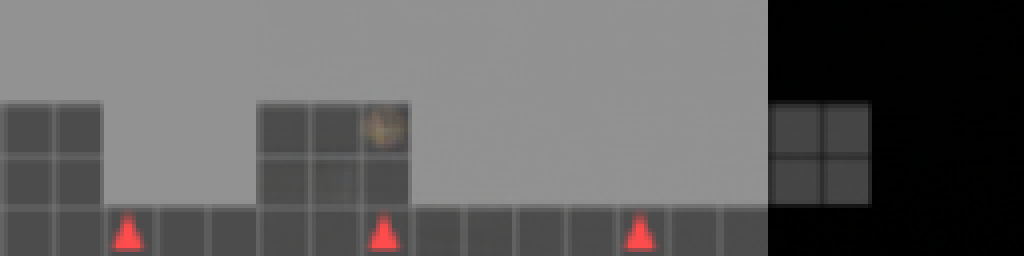

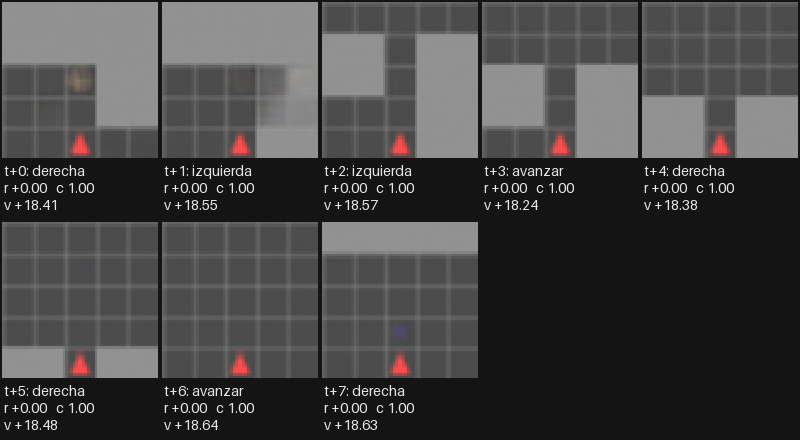

In [7]:
# Prueba sin interfaz: 12 pasos al azar y una imaginación del actor.
# Fila: vista real | reconstrucción (viendo) | sueño (sin ver) | error.
RUN_EXPLORAR = RUNS[NOMBRE_RUN] if NOMBRE_RUN in RUNS else next(iter(RUNS.values()))  # cambia el run aquí

!cd /content/r2dreamer-cookie && .venv/bin/python explorar_modelo.py --logdir "{RUN_EXPLORAR}" --prueba /content/prueba.png 2>&1 | tail -n 9

from pathlib import Path
from IPython.display import Image as Img, display
if Path("/content/prueba.png").exists():
    display(Img("/content/prueba.png"), Img("/content/prueba.actor.png"))
else:
    print("La prueba falló: revisa el error de arriba.")

In [8]:
# Define cómo abrir un explorador. Cada run corre en su propio proceso y puerto,
# así que puedes tener varios abiertos a la vez (uno por celda).
import socket, subprocess, time, urllib.request
from google.colab import output

REPO = "/content/r2dreamer-cookie"
assert "data:image/png" in open(f"{REPO}/explorar_modelo.py").read(), \
    "explorar_modelo.py es la versión vieja: vuelve a correr la celda %%writefile con el código nuevo."


def abrir_explorador(nombre_run, alto=1500):
    run = RUNS[nombre_run]
    # Cierra solo el explorador anterior de ESTE run (los de otros runs siguen abiertos).
    subprocess.run(["pkill", "-9", "-f", f"explorar_modelo.py --logdir {run} --port"])
    time.sleep(2)
    with socket.socket() as s:
        s.bind(("127.0.0.1", 0))
        puerto = s.getsockname()[1]
    archivo_log = f"/content/explorar_{nombre_run}.log"
    proceso = subprocess.Popen(
        [f"{REPO}/.venv/bin/python", "-u", "explorar_modelo.py", "--logdir", str(run), "--port", str(puerto)],
        cwd=REPO, stdout=open(archivo_log, "w"), stderr=subprocess.STDOUT,
    )
    for _ in range(300):
        if proceso.poll() is not None:
            raise RuntimeError(open(archivo_log).read()[-3000:])
        try:
            urllib.request.urlopen(f"http://127.0.0.1:{puerto}", timeout=1)
            break
        except Exception:
            time.sleep(1)
    print(f"Run: {nombre_run}  (puerto {puerto})")
    output.serve_kernel_port_as_iframe(puerto, height=alto)
    # Para abrirlo en una pestaña aparte: output.serve_kernel_port_as_window(puerto)

### Cómo usarlo

- **← → ↑** (o los botones): izquierda, derecha y avanzar. Haz clic una vez dentro de la página para que tome el teclado.
- Cada acción mueve el entorno real **y** el sueño. *Viendo* (posterior) recibe la imagen real en cada paso; *soñando* (prior) solo recibe las acciones desde la última sincronización.
- **S**: sincroniza el sueño con la realidad. **A**: juega la acción más probable del actor. *El actor juega N pasos* repite eso N veces.
- **Solo soñar**: desmarca *Mover también el entorno real* para pasear por el sueño sin tocar el entorno. Sirve, por ejemplo, para imaginar que apretó el botón y ver dónde cree que aparece la galleta.
- **Imaginación del actor**: muestra lo que el actor "ve" al aprender, o sea, 15 pasos jugando dentro del sueño desde el estado actual, con la recompensa, el `continue` y el valor predichos.

### Qué buscar

| Lo que ves | Qué falla |
|---|---|
| La reconstrucción (*viendo*) pierde el botón, la galleta o las paredes | Representación: el latente no guarda eso |
| La reconstrucción está bien, pero el sueño se deforma a los pocos pasos sin ver | Dinámica |
| Al girar y volver, el sueño "olvida" lo que había (con vista parcial) | Memoria del estado determinista |
| Comes una galleta real y la *recompensa predicha* no sube | Cabeza de recompensa: pocos ejemplos con recompensa en el replay |
| Todo lo anterior está bien, pero la imaginación del actor da vueltas sin rumbo | Actor-crítico: valor plano, horizonte o entropía |
| Con *El actor juega N pasos* el agente real se queda girando, pero en la imaginación del actor la recompensa y el valor siguen altos | Datos solo del experto: el modelo no conoce los estados a los que llega el actor y los sueña como si fueran del experto |
| Llevas al agente a mano por el camino del experto y el sueño aguanta muchos pasos, pero si te desvías se deforma enseguida | Lo mismo: el modelo solo es bueno donde hubo datos |

### Para este run (datos del experto)

1. Aprieta **El actor juega N pasos** con N=50 y mira si el agente real avanza o se queda girando, y qué recompensa y valor predice mientras tanto.
2. Abre **Imaginación del actor** desde ese mismo estado: ¿el sueño muestra al agente llegando al botón o a la galleta aunque en la realidad no se mueve?
3. Reinicia y lleva al agente a mano hasta el botón y luego a la galleta (lo que haría el experto). Comprueba que la *recompensa predicha* sube al comerla y que el sueño aguanta varios pasos sin ver.
4. Repite, pero desviándote a propósito (girar en el pasillo, chocar con paredes). Si el sueño se rompe mucho antes que en el paso 3, el modelo solo aprendió las trayectorias del experto.

In [9]:
abrir_explorador(Path(RUN_EXPLORAR).name)

Run: cookie_partial_hall5_view5_s0_expert_local  (puerto 60869)


<IPython.core.display.Javascript object>

## 5. TensorBoard: el desempeño durante el entrenamiento

Todo lo de `metrics.jsonl` también está en `events.out.tfevents...`, junto con los videos de predicción. Este archivo pesa ~690 MB, sobre todo por los videos, y leerlo directo desde Drive es lento. Por eso la celda siguiente lo **copia primero al disco de Colab** (`/content/tb/<run>`), y TensorBoard lee desde ahí.

**Qué mirar en cada pestaña**

| Pestaña | Etiqueta | Qué te dice |
|---|---|---|
| Scalars | `episode/eval_score` | Galletas del actor en evaluación (5 episodios cada 25k pasos). Es la métrica principal. |
| Scalars | `episode/score`, `episode/score_expert` | Galletas en los episodios que llenaron el replay (aquí, los del experto). Es el techo que el actor podría imitar. |
| Scalars | `episode/eval_presses`, `episode/eval_cells`, `episode/eval_button_room` | Qué hace el actor: cuántas veces aprieta el botón, cuántas celdas visita y cuántos pasos pasa en la pieza del botón. |
| Scalars | `train/loss/image`, `train/loss/dyn`, `train/loss/rep` | Modelo de mundo: reconstrucción y KL entre posterior y prior. Si `dyn` queda en ~1, está en el `kl_free`. |
| Scalars | `train/loss/rew`, `train/loss/con`, `train/rew` | Cabezas de recompensa y `continue`. |
| Scalars | `train/val`, `train/tar`, `train/value_replay_*`, `train/ret_replay_*` | Crítico: valor en la imaginación y sobre el replay. Compara la media con la desviación para ver si el valor es plano. |
| Scalars | `train/action_entropy`, `train/adv`, `train/loss/policy` | Actor: si la entropía cae a ~0 muy temprano, la política se volvió casi determinista. |
| Images | `open_loop` | Predicciones sobre el replay: arriba lo real, al medio el modelo (5 pasos viendo y luego soñando) y abajo el error. |
| Images | `eval_open_loop`, `eval_video` | Lo mismo, pero sobre episodios del **actor** en evaluación, que son justo los estados que el experto no visitó. Si `open_loop` se ve bien y `eval_open_loop` mal, el modelo solo aprendió las trayectorias del experto. |

**Consejos**

- En *Scalars*, sube el *Smoothing* a ~0,8 para las métricas `train/*` y bájalo a 0 para `episode/eval_*` (hay pocos puntos).
- Para ver todos los videos y no solo una muestra, se usa `--samples_per_plugin images=0` (ya está en la celda).
- Si tienes varios runs en subcarpetas de `/content/tb`, TensorBoard los superpone con colores distintos y puedes compararlos.